<a href="https://colab.research.google.com/github/Harshini-Bhandary21/AIML_LAB_PRACTICALS/blob/main/Harshini_AIML_Practical_6_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML Assignment 6

Name: Harshini Ramdas Bhandary  
PRN: 202401040151  
Roll no: 35  
Div: A  Batch: A2  
GitHub lab repo: https://github.com/Harshini-Bhandary21/AIML_LAB_PRACTICALS

## 1. Title
Clustering Algorithms on a Real-World Wine Dataset: K-Means, Hierarchical, DBSCAN and Gaussian Mixture

## 2. Aim
The aim of this experiment is to apply clustering algorithms on a real-world dataset, find the natural groups that exist in the data without using any labels, and judge how good those groups are using metrics such as the silhouette score and the Davies-Bouldin index, along with visual inspection.

## 3. Experiment Objectives
1. To load a real-world dataset and prepare it for clustering (scaling and a quick look at the data).
2. To implement four clustering algorithms: K-Means, Agglomerative (hierarchical) clustering, DBSCAN and Gaussian Mixture Model (GMM).
3. To find a suitable number of clusters using the elbow method, silhouette score, Davies-Bouldin index, Calinski-Harabasz score and a dendrogram.
4. To evaluate the clusters using internal metrics (silhouette, Davies-Bouldin, Calinski-Harabasz) and by visual inspection.
5. To double check the result using the real labels with ARI, NMI and homogeneity, which are not used in the fitting.
6. To understand what each cluster means by looking at the average feature values of the cluster.
7. To test a few improvements (scaling, PCA, stability) and write down what the results show.

## 4. Experiment Outcomes
After running the program, all four clustering methods were applied on the wine data and compared with the same set of metrics.

Three clusters were found to be the best choice for K-Means, hierarchical clustering and GMM. K-Means gave the best result, with a silhouette score of 0.285 and a Davies-Bouldin index of 1.389. Its clusters also matched the real wine types very well (ARI 0.897). DBSCAN did not suit this data and treated almost one third of the samples as noise.

An important finding was that the silhouette score alone can be misleading. Clustering the unscaled data gave a much higher silhouette score (0.571) but a very poor match with the real wine types (ARI 0.371). This is explained in the result analysis.

The clusters were also described in simple words by looking at their average chemical values, and their stability was tested by clustering random 80% parts of the data many times.

## 5. Conceptual Details

### 5.1 What is clustering
Clustering is a kind of unsupervised learning. We do not give the algorithm any correct answers or labels. It only looks at the features of the samples and tries to put similar samples in the same group and different samples in different groups. It is used for things like customer segmentation, grouping documents, and finding patterns in medical or chemical data.

### 5.2 K-Means
K-Means needs the number of clusters k in advance. It starts with k random centres, assigns every sample to its nearest centre, moves each centre to the average of its samples, and repeats this until the centres stop moving. It is fast and simple, and it works best when clusters are roughly round and similar in size. Since the starting centres are random, the algorithm is run many times (n_init = 20) and the best result is kept.

### 5.3 Agglomerative (hierarchical) clustering
Here every sample starts as its own cluster. At each step the two closest clusters are merged, until only one cluster is left. The history of merges can be drawn as a tree called a dendrogram, and cutting the tree at a chosen height gives the clusters. Ward linkage is used, which merges the pair of clusters that increases the total spread the least.

### 5.4 DBSCAN
DBSCAN groups together points that are packed closely. It has two settings: eps, the radius of the neighbourhood, and min_samples, the number of points needed to form a dense area. Points in dense areas form clusters, and points which are not close to any dense area are labelled as noise. It does not need the number of clusters and it can find clusters of any shape, but it struggles when the density of the data is uneven or when there are many features.

### 5.5 Gaussian Mixture Model
GMM assumes that the data comes from a mix of several bell-shaped (Gaussian) distributions. It finds the shape and position of each one, and gives every sample a probability of belonging to each cluster. This is a soft version of K-Means and it can handle clusters that are stretched in some direction.

### 5.6 Evaluation metrics
When there are no labels we use internal metrics, which only look at the data and the clusters.

Silhouette score compares, for every sample, how close it is to its own cluster and how far it is from the nearest other cluster. It goes from -1 to 1, and higher is better. A negative value means the sample is probably in the wrong cluster.

Davies-Bouldin index measures how similar each cluster is to its most similar neighbour, using the spread inside the clusters and the distance between the centres. Lower is better, and 0 is the best possible.

Calinski-Harabasz score is the ratio of the spread between clusters to the spread inside clusters. Higher is better.

When the real labels are known, they can be used only to check the result afterwards (external metrics). Adjusted Rand Index (ARI) tells how well two groupings agree, where 1 is a perfect match and 0 is what random grouping would give. Normalised Mutual Information (NMI) measures the shared information between the clusters and the real labels, and homogeneity tells whether every cluster contains samples from only one real class.

### 5.7 Dataset
The Wine dataset from scikit-learn is used. It contains the result of a chemical analysis of 178 wines grown in the same region of Italy, from 3 different grape cultivars. Each wine has 13 measurements such as alcohol, flavanoids, colour intensity and proline. There are no missing values. The cultivar label is available but it is kept aside and is not used for clustering, so we can later check whether the algorithms found the real groups on their own.

### 5.8 Why these methods and this dataset were chosen
The four methods work on four different ideas. K-Means is based on distance to a centre, hierarchical clustering is based on merging the closest groups, DBSCAN is based on density, and GMM is based on probability distributions. Using all four shows how the answer depends on the idea that the algorithm follows, and it makes the comparison fair and useful.

The wine data was chosen because it is real data, it is small enough to try many settings, all its features are numeric, and it has known cultivars, which gives an independent way to check the clusters. Most clustering datasets do not have this. Since the features are on very different scales (proline is in hundreds and hue is close to 1), scaling is needed, and this is tested in the experiment instead of just being assumed.

## 6. Algorithm / Flowchart Details

### 6.1 Main algorithm
Step 1: Start the program and import the libraries.  
Step 2: Load the wine dataset and keep the real labels aside.  
Step 3: Look at the data: summary values and correlation between features.  
Step 4: Standardise all the features so that every feature has mean 0 and standard deviation 1.  
Step 5: Use PCA to get a 2D version of the data, only for drawing pictures.  
Step 6: For k = 2 to 10, run K-Means, hierarchical clustering and GMM, and calculate the elbow, silhouette, Davies-Bouldin, Calinski-Harabasz and BIC values.  
Step 7: Draw the dendrogram and check where the tree should be cut.  
Step 8: For DBSCAN, draw the k-distance plot, try a grid of eps and min_samples values, and choose one using a fixed rule.  
Step 9: Fit the final four models and calculate the internal and external metrics.  
Step 10: Draw the clusters on the 2D plot and draw the silhouette plot.  
Step 11: Describe every cluster using its average feature values.  
Step 12: Test the improvements: effect of scaling, effect of PCA, and stability of the clusters.  
Step 13: Write the conclusion and stop.

### 6.2 Flowchart
The flowchart is drawn below using matplotlib. The same picture is also saved as flowchart_clustering.png.

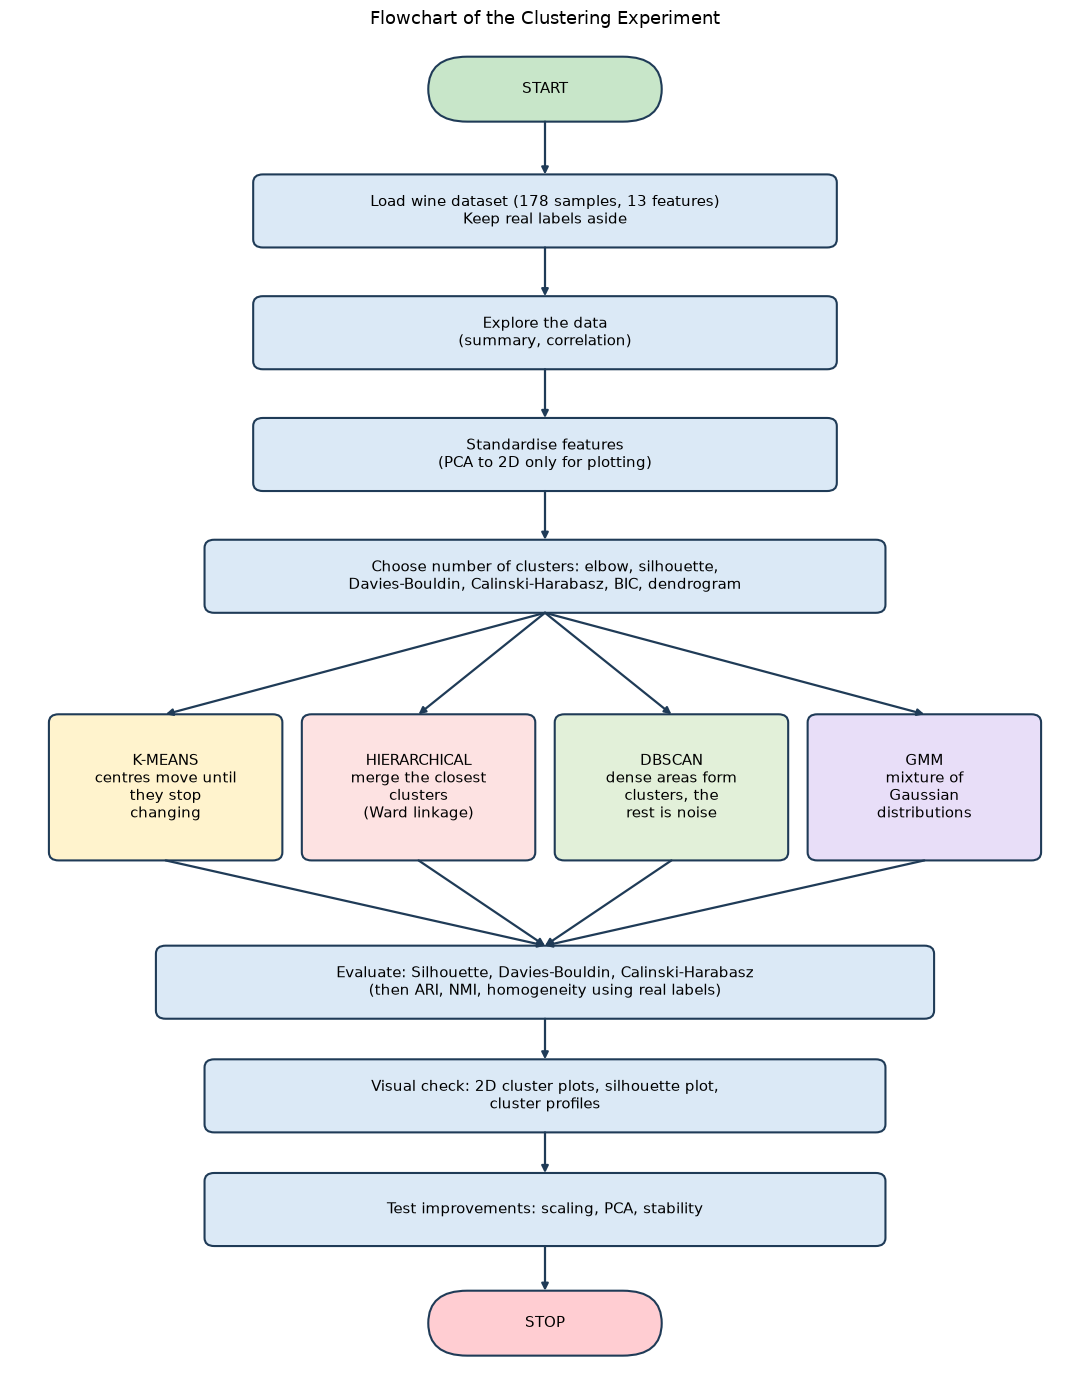

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 14))
ax.set_xlim(0, 11); ax.axis("off")

def box(x, y, w, h, text, color="#dbe9f6", rounded=False):
    style = "round,pad=0,rounding_size=0.4" if rounded else "round,pad=0,rounding_size=0.1"
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle=style, fc=color, ec="#1f3b57", lw=1.5))
    ax.text(x, y, text, ha="center", va="center", fontsize=10.5)
    return dict(x=x, top=y + h/2, bottom=y - h/2)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#1f3b57", shrinkA=0, shrinkB=0))

start = box(5.5, 15.0, 2.4, 0.8, "START", "#c8e6c9", True)
load  = box(5.5, 13.5, 6.0, 0.9, "Load wine dataset (178 samples, 13 features)\nKeep real labels aside")
eda   = box(5.5, 12.0, 6.0, 0.9, "Explore the data\n(summary, correlation)")
scale = box(5.5, 10.5, 6.0, 0.9, "Standardise features\n(PCA to 2D only for plotting)")
findk = box(5.5, 9.0, 7.0, 0.9, "Choose number of clusters: elbow, silhouette,\nDavies-Bouldin, Calinski-Harabasz, BIC, dendrogram")
for a, b in [(start, load), (load, eda), (eda, scale), (scale, findk)]:
    arrow(5.5, a["bottom"], 5.5, b["top"])

km = box(1.6, 6.4, 2.4, 1.8, "K-MEANS\ncentres move until\nthey stop\nchanging", "#fff3cd")
hc = box(4.2, 6.4, 2.4, 1.8, "HIERARCHICAL\nmerge the closest\nclusters\n(Ward linkage)", "#fde2e2")
db = box(6.8, 6.4, 2.4, 1.8, "DBSCAN\ndense areas form\nclusters, the\nrest is noise", "#e2f0d9")
gm = box(9.4, 6.4, 2.4, 1.8, "GMM\nmixture of\nGaussian\ndistributions", "#e8def8")
for s in (km, hc, db, gm):
    arrow(5.5, findk["bottom"], s["x"], s["top"])

ev = box(5.5, 4.0, 8.0, 0.9, "Evaluate: Silhouette, Davies-Bouldin, Calinski-Harabasz\n(then ARI, NMI, homogeneity using real labels)")
for s in (km, hc, db, gm):
    arrow(s["x"], s["bottom"], 5.5, ev["top"])

vis  = box(5.5, 2.6, 7.0, 0.9, "Visual check: 2D cluster plots, silhouette plot,\ncluster profiles")
imp  = box(5.5, 1.2, 7.0, 0.9, "Test improvements: scaling, PCA, stability")
stop = box(5.5, -0.2, 2.4, 0.8, "STOP", "#ffcdd2", True)
for a, b in [(ev, vis), (vis, imp), (imp, stop)]:
    arrow(5.5, a["bottom"], 5.5, b["top"])
ax.set_ylim(-0.9, 15.7)

plt.title("Flowchart of the Clustering Experiment", fontsize=13)
plt.tight_layout(); plt.show()

## 7. Code (Implementation)

### 7.1 Importing the libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_style("whitegrid")

### 7.2 Loading the dataset
The real labels are stored in y_true but they are not used for clustering.

In [ ]:
# Load the wine dataset (real chemical analysis of wines from 3 grape cultivars)
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target     # kept aside, only used at the very end to double-check the clusters

print("Shape of data  :", X.shape)
print("Missing values :", int(X.isnull().sum().sum()))
X.head()

Shape of data  : (178, 13)
Missing values : 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### 7.3 A first look at the data

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


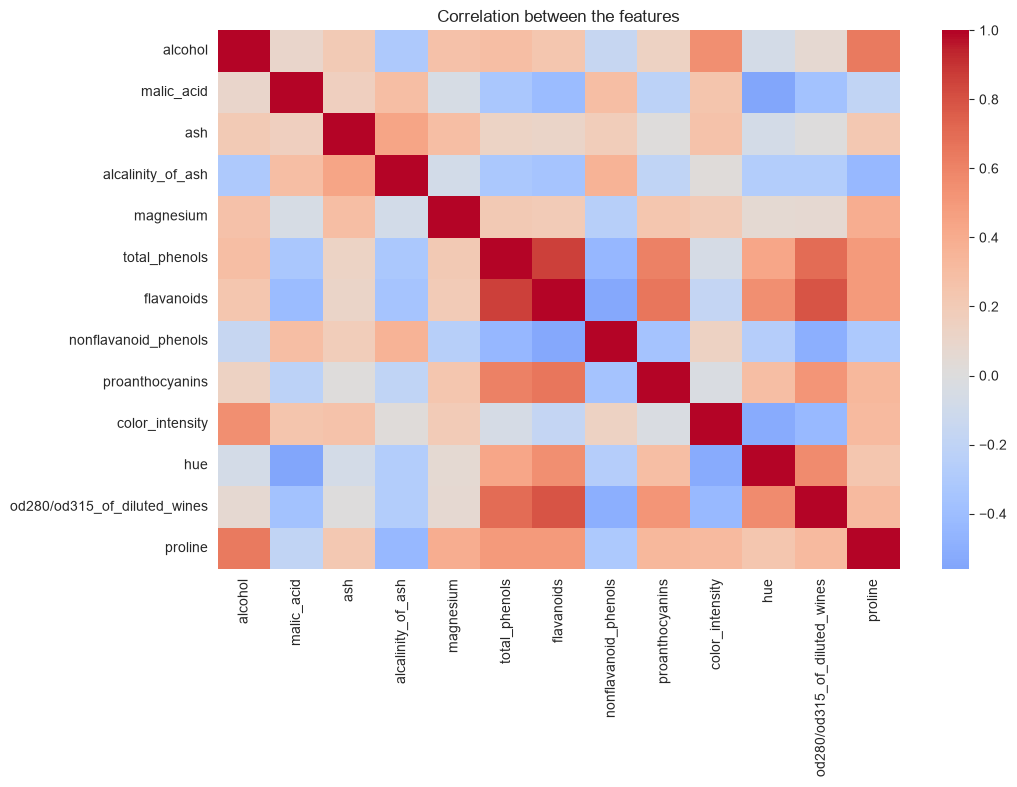

In [ ]:
# Basic look at the data
display(X.describe().T[["mean", "std", "min", "max"]].round(2))

plt.figure(figsize=(11, 7))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation between the features")
plt.show()

### 7.4 Scaling the features and preparing a 2D view
The features are very different in range, so they are standardised. PCA is used only to draw the clusters in two dimensions, the clustering itself uses all 13 scaled features.

Variance explained by the 2 PCA axes: [0.362 0.192] | total = 0.554


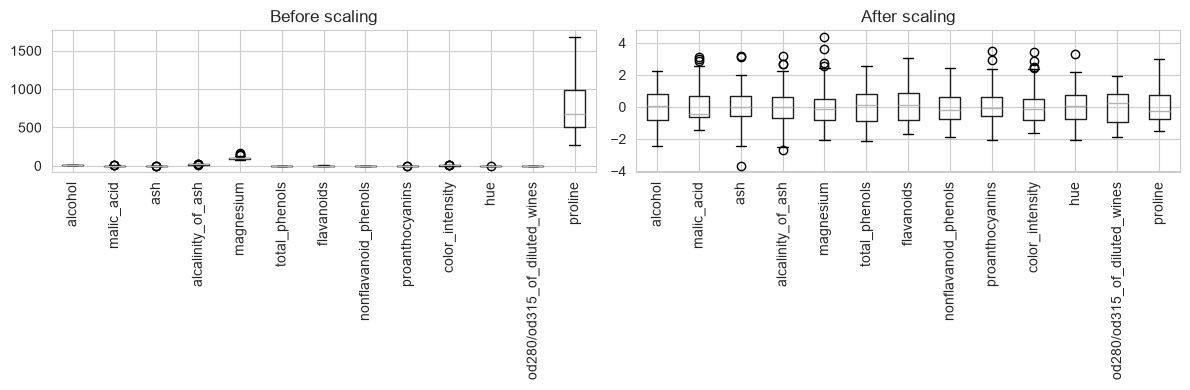

In [ ]:
# Features are in very different ranges (proline is in hundreds, hue is near 1),
# so they are standardised before clustering.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA is used only to draw 2D pictures of the clusters
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X_scaled)
print("Variance explained by the 2 PCA axes:", pca.explained_variance_ratio_.round(3),
      "| total =", round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
X.boxplot(ax=ax[0], rot=90); ax[0].set_title("Before scaling")
pd.DataFrame(X_scaled, columns=X.columns).boxplot(ax=ax[1], rot=90); ax[1].set_title("After scaling")
plt.tight_layout(); plt.show()

### 7.5 Helper functions for the metrics

In [ ]:
# One small function that gives all the internal scores for a set of labels
def internal_scores(data, labels):
    mask = labels != -1                       # ignore DBSCAN noise points when scoring
    if len(set(labels[mask])) < 2:
        return dict(Silhouette=np.nan, Davies_Bouldin=np.nan, Calinski_Harabasz=np.nan)
    return dict(Silhouette=silhouette_score(data[mask], labels[mask]),
                Davies_Bouldin=davies_bouldin_score(data[mask], labels[mask]),
                Calinski_Harabasz=calinski_harabasz_score(data[mask], labels[mask]))

# Scores that use the real wine labels (only to check the result, never used for fitting)
def external_scores(labels):
    mask = labels != -1
    return dict(ARI=adjusted_rand_score(y_true[mask], labels[mask]),
                NMI=normalized_mutual_info_score(y_true[mask], labels[mask]),
                Homogeneity=homogeneity_score(y_true[mask], labels[mask]))

### 7.6 Choosing the number of clusters
K-Means, hierarchical clustering and GMM are run for k from 2 to 10 and all the scores are collected in one table.

In [ ]:
# How many clusters? Try k = 2 to 10 for K-Means, Hierarchical and Gaussian Mixture
ks = range(2, 11)
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    hc = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X_scaled)
    gm = GaussianMixture(n_components=k, n_init=5, random_state=RANDOM_STATE).fit(X_scaled)
    rows.append({"k": k,
                 "KMeans inertia": km.inertia_,
                 "KMeans silhouette": silhouette_score(X_scaled, km.labels_),
                 "KMeans DB": davies_bouldin_score(X_scaled, km.labels_),
                 "KMeans CH": calinski_harabasz_score(X_scaled, km.labels_),
                 "Hier. silhouette": silhouette_score(X_scaled, hc.labels_),
                 "GMM silhouette": silhouette_score(X_scaled, gm.predict(X_scaled)),
                 "GMM BIC": gm.bic(X_scaled)})
kdf = pd.DataFrame(rows).set_index("k")
kdf.round(3)

,KMeans inertia,KMeans silhouette,KMeans DB,KMeans CH,Hier. silhouette,GMM silhouette,GMM BIC
k,,,,,,,
2,1658.759,0.259,1.526,69.523,0.267,0.269,5608.350
3,1277.928,0.285,1.389,70.940,0.277,0.284,5806.285
4,1175.352,0.259,1.817,56.189,0.226,0.254,5806.820
5,1107.007,0.232,1.681,47.156,0.187,0.225,6026.114
6,1046.002,0.237,1.554,41.701,0.180,0.166,6353.354
7,981.595,0.204,1.661,38.686,0.187,0.127,6709.890
8,935.201,0.157,1.741,35.805,0.188,0.163,6407.919
9,889.893,0.150,1.708,33.807,0.192,0.167,6448.656
10,845.895,0.144,1.707,32.397,0.199,0.148,6645.412


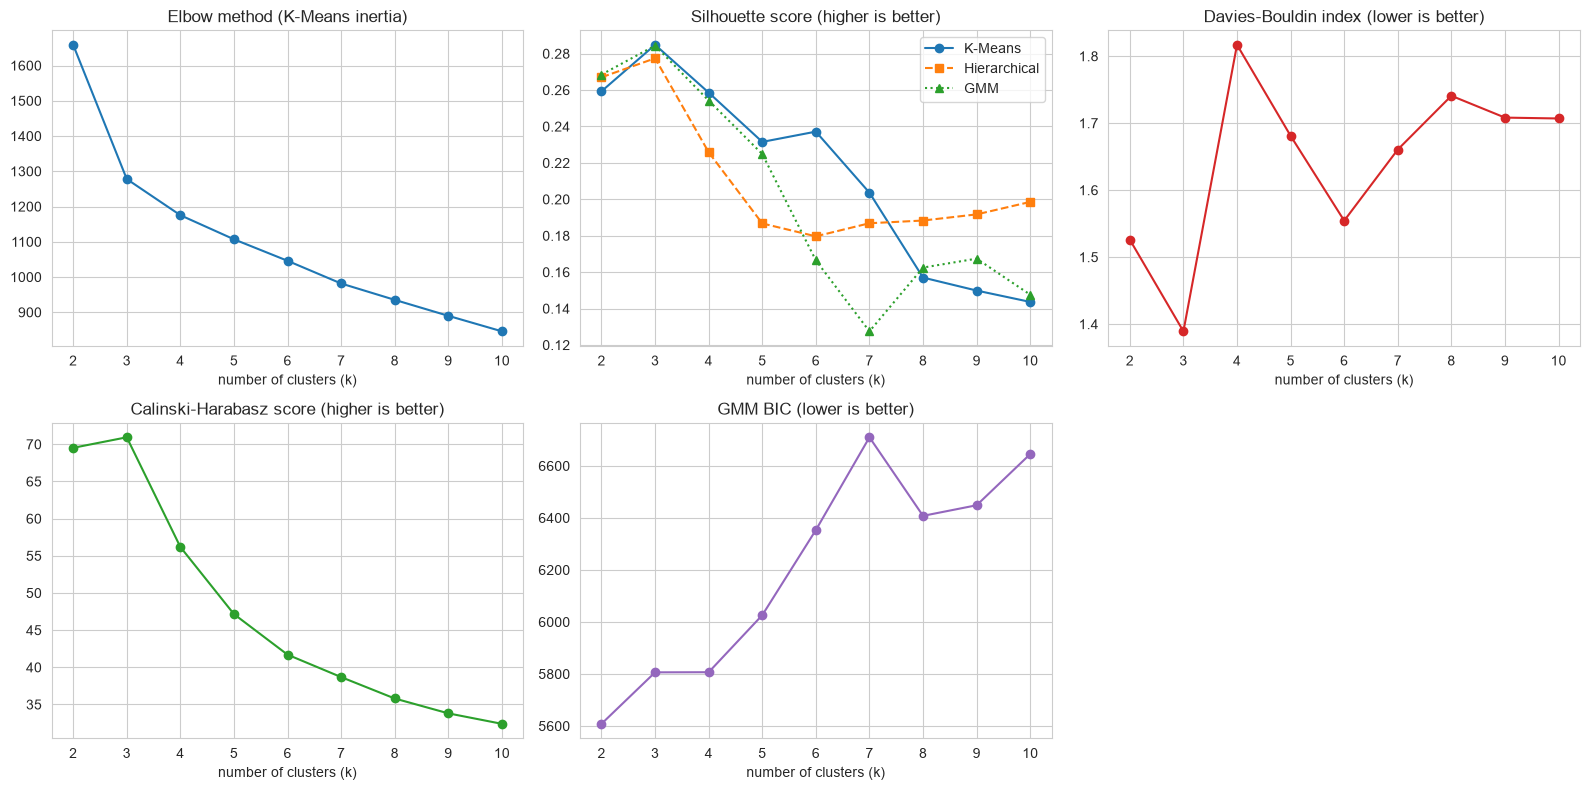

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax = ax.ravel()
ax[0].plot(kdf.index, kdf["KMeans inertia"], "o-"); ax[0].set_title("Elbow method (K-Means inertia)")
ax[1].plot(kdf.index, kdf["KMeans silhouette"], "o-", label="K-Means")
ax[1].plot(kdf.index, kdf["Hier. silhouette"], "s--", label="Hierarchical")
ax[1].plot(kdf.index, kdf["GMM silhouette"], "^:", label="GMM"); ax[1].legend(); ax[1].set_title("Silhouette score (higher is better)")
ax[2].plot(kdf.index, kdf["KMeans DB"], "o-", color="tab:red"); ax[2].set_title("Davies-Bouldin index (lower is better)")
ax[3].plot(kdf.index, kdf["KMeans CH"], "o-", color="tab:green"); ax[3].set_title("Calinski-Harabasz score (higher is better)")
ax[4].plot(kdf.index, kdf["GMM BIC"], "o-", color="tab:purple"); ax[4].set_title("GMM BIC (lower is better)")
ax[5].axis("off")
for a in ax[:5]:
    a.set_xlabel("number of clusters (k)")
plt.tight_layout(); plt.show()

### 7.7 Dendrogram

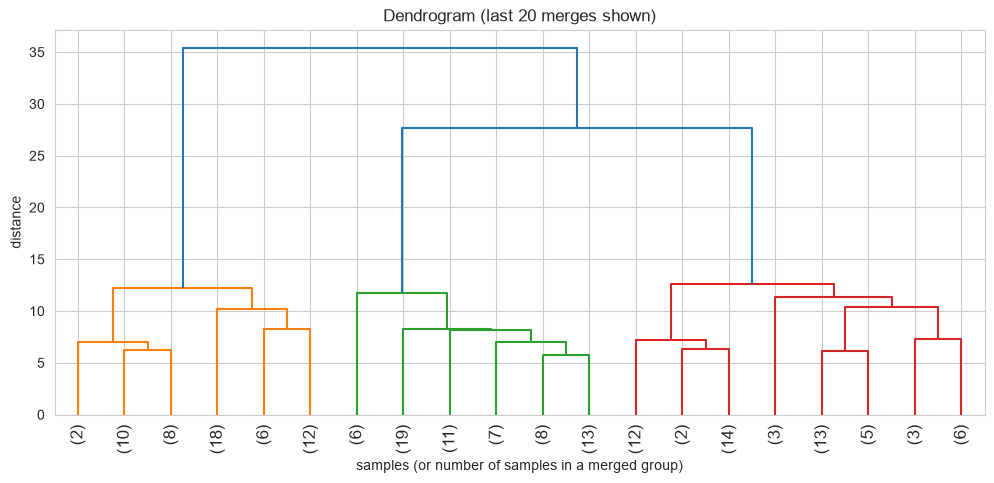

In [ ]:
# Dendrogram for hierarchical clustering (Ward linkage)
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90, color_threshold=0.7 * max(Z[:, 2]))
plt.title("Dendrogram (last 20 merges shown)")
plt.xlabel("samples (or number of samples in a merged group)"); plt.ylabel("distance")
plt.show()

### 7.8 DBSCAN settings
Eps and min_samples are chosen with a fixed rule so that the choice is not just a guess: at least 2 clusters, not more than 35% of the samples labelled as noise, and then the highest silhouette score.

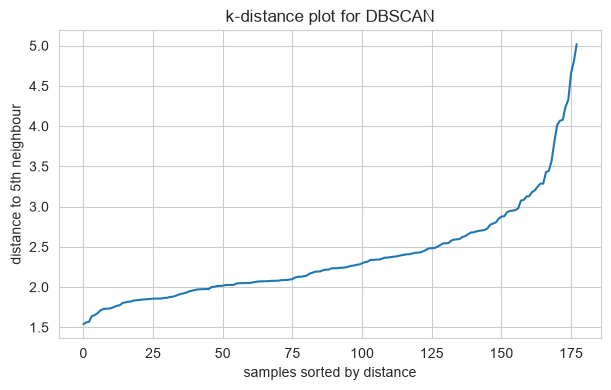

Chosen DBSCAN setting: eps = 2.2 , min_samples = 5


,eps,min_samples,clusters,noise points,silhouette (no noise)
0,1.8,3,8,90,0.312
1,1.8,5,7,118,0.246
2,1.8,8,1,170,NaN
3,2.0,3,5,64,0.211
4,2.0,5,5,85,0.240
5,2.0,8,3,117,0.436
6,2.2,3,3,44,0.073
7,2.2,5,2,55,0.348
8,2.2,8,2,67,0.350
9,2.4,3,2,28,0.314


In [ ]:
# DBSCAN needs eps and min_samples. First look at the k-distance plot to pick a sensible eps.
min_samples = 5
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
dist = np.sort(nn.kneighbors(X_scaled)[0][:, -1])
plt.figure(figsize=(7, 4))
plt.plot(dist); plt.xlabel("samples sorted by distance"); plt.ylabel(f"distance to {min_samples}th neighbour")
plt.title("k-distance plot for DBSCAN")
plt.show()

# Then try a small grid of eps / min_samples values and look at what comes out
rows = []
for eps in [1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0]:
    for ms in [3, 5, 8]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        s = internal_scores(X_scaled, lab)["Silhouette"]
        rows.append({"eps": eps, "min_samples": ms, "clusters": n_cl,
                     "noise points": int((lab == -1).sum()), "silhouette (no noise)": s})
dbdf = pd.DataFrame(rows)

# Rule used to pick the setting: at least 2 clusters, no more than 35% of the samples treated as noise,
# and then the best silhouette among those.
ok = dbdf[(dbdf["clusters"] >= 2) & (dbdf["noise points"] <= 0.35 * len(X_scaled))]
best = ok.sort_values("silhouette (no noise)", ascending=False).iloc[0]
DB_EPS, DB_MS = float(best["eps"]), int(best["min_samples"])
print("Chosen DBSCAN setting: eps =", DB_EPS, ", min_samples =", DB_MS)
dbdf.round(3)

### 7.9 Final models and comparison
The final models use k = 3 for K-Means, hierarchical clustering and GMM. For DBSCAN, the silhouette-type scores are calculated after removing the noise points, which makes the DBSCAN numbers look a little better than they really are.

In [ ]:
# Final models, all with 3 clusters (chosen from the k analysis above)
K = 3
final = {}
final["K-Means"]      = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
final["Hierarchical"] = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_scaled)
final["GMM"]          = GaussianMixture(n_components=K, n_init=5, random_state=RANDOM_STATE).fit(X_scaled).predict(X_scaled)
final["DBSCAN"]       = DBSCAN(eps=DB_EPS, min_samples=DB_MS).fit_predict(X_scaled)

rows = []
for name, lab in final.items():
    row = {"Method": name,
           "Clusters": len(set(lab)) - (1 if -1 in lab else 0),
           "Noise points": int((lab == -1).sum())}
    row.update(internal_scores(X_scaled, lab))
    row.update(external_scores(lab))
    rows.append(row)
res = pd.DataFrame(rows).set_index("Method")
res.round(3)

,Clusters,Noise points,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity
Method,,,,,,,,
K-Means,3,0,0.285,1.389,70.940,0.897,0.876,0.879
Hierarchical,3,0,0.277,1.419,67.647,0.790,0.786,0.790
GMM,3,0,0.284,1.394,70.688,0.880,0.861,0.864
DBSCAN,2,55,0.348,1.124,68.391,0.525,0.676,0.528


### 7.10 Visual inspection of the clusters

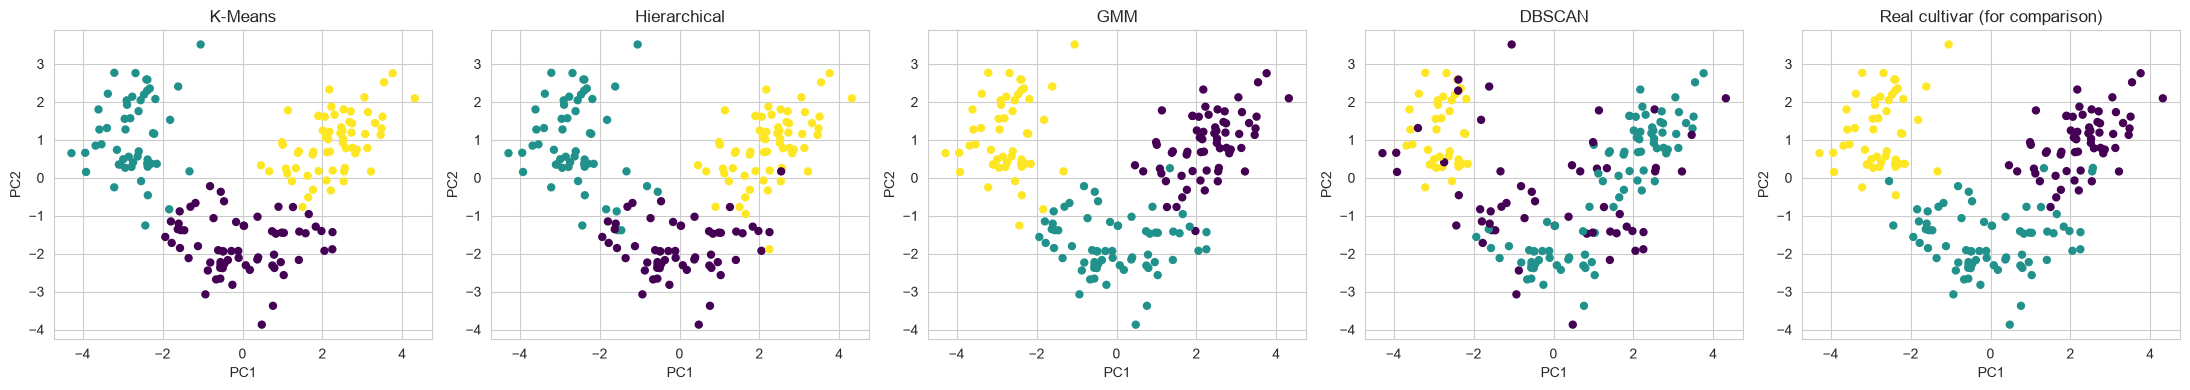

In [ ]:
# Pictures of the clusters in the 2D PCA space
fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for a, (name, lab) in zip(ax, final.items()):
    a.scatter(X_2d[:, 0], X_2d[:, 1], c=lab, cmap="viridis", s=25)
    a.set_title(name); a.set_xlabel("PC1"); a.set_ylabel("PC2")
ax[4].scatter(X_2d[:, 0], X_2d[:, 1], c=y_true, cmap="viridis", s=25)
ax[4].set_title("Real cultivar (for comparison)"); ax[4].set_xlabel("PC1"); ax[4].set_ylabel("PC2")
plt.tight_layout(); plt.show()

### 7.11 Silhouette plot of K-Means

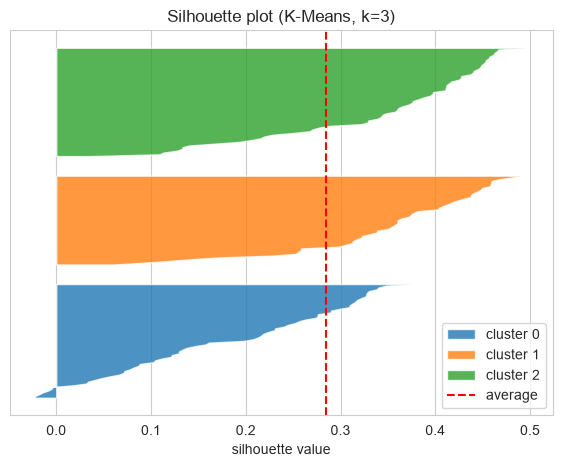

Samples with negative silhouette (probably in the wrong cluster): 7


In [ ]:
# Silhouette plot for K-Means: shows how well every single sample fits its cluster
lab = final["K-Means"]
sil = silhouette_samples(X_scaled, lab)
plt.figure(figsize=(7, 5))
y_low = 10
for c in range(K):
    vals = np.sort(sil[lab == c])
    plt.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals, alpha=0.8, label=f"cluster {c}")
    y_low += len(vals) + 10
plt.axvline(silhouette_score(X_scaled, lab), color="red", linestyle="--", label="average")
plt.xlabel("silhouette value"); plt.yticks([]); plt.legend(); plt.title("Silhouette plot (K-Means, k=3)")
plt.show()
print("Samples with negative silhouette (probably in the wrong cluster):", int((sil < 0).sum()))

### 7.12 What does each cluster mean

,0,1,2
size,65.00,51.00,62.00
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92


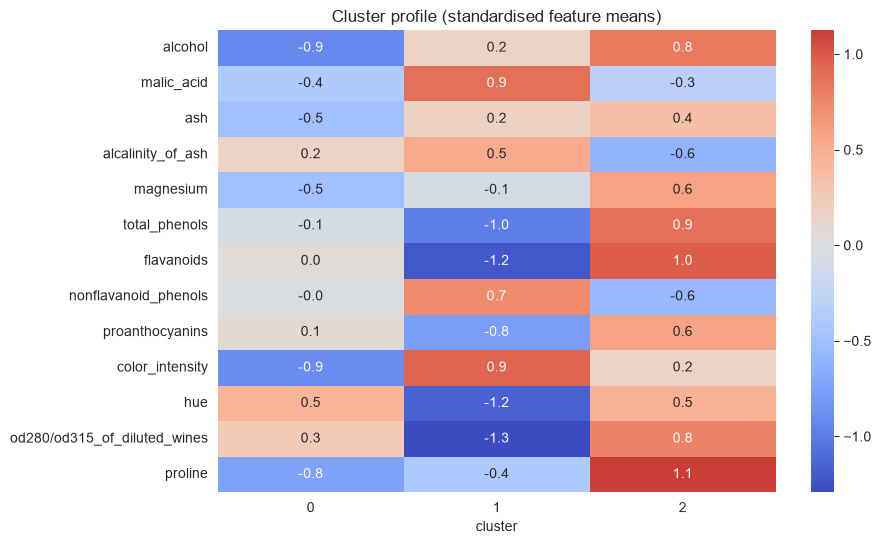

In [ ]:
# What does each K-Means cluster mean? Average of every feature per cluster (original units)
profile = X.groupby(final["K-Means"]).mean()
profile.insert(0, "size", pd.Series(final["K-Means"]).value_counts().sort_index())
display(profile.round(2).T)

# Which features differ most between clusters (in standardised units)?
z_profile = pd.DataFrame(X_scaled, columns=X.columns).groupby(final["K-Means"]).mean()
plt.figure(figsize=(9, 6))
sns.heatmap(z_profile.T, cmap="coolwarm", center=0, annot=True, fmt=".1f")
plt.xlabel("cluster"); plt.title("Cluster profile (standardised feature means)")
plt.show()

### 7.13 Improvement test 1: does scaling matter

In [ ]:
# Improvement test 1: does scaling really matter?
rows = []
for name, data in [("Raw data (no scaling)", X.values), ("Scaled data", X_scaled)]:
    lab = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE).fit_predict(data)
    r = {"Input": name, "Silhouette (in own space)": silhouette_score(data, lab)}
    r.update(external_scores(lab))
    rows.append(r)
pd.DataFrame(rows).set_index("Input").round(3)

,Silhouette (in own space),ARI,NMI,Homogeneity
Input,,,,
Raw data (no scaling),0.571,0.371,0.429,0.429
Scaled data,0.285,0.897,0.876,0.879


### 7.14 Improvement test 2: clustering after PCA

In [ ]:
# Improvement test 2: cluster on PCA-reduced data instead of all 13 features
rows = []
for n in [2, 3, 5, 8, 13]:
    Xp = PCA(n_components=n, random_state=RANDOM_STATE).fit_transform(X_scaled)
    lab = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE).fit_predict(Xp)
    r = {"PCA components": n, "Silhouette (in own space)": silhouette_score(Xp, lab)}
    r.update(external_scores(lab))
    rows.append(r)
pd.DataFrame(rows).set_index("PCA components").round(3)

,Silhouette (in own space),ARI,NMI,Homogeneity
PCA components,,,,
2,0.561,0.895,0.882,0.884
3,0.453,0.880,0.861,0.864
5,0.369,0.897,0.876,0.879
8,0.315,0.897,0.876,0.879
13,0.285,0.897,0.876,0.879


### 7.15 Improvement test 3: stability of the clusters
Each method is run 30 times on a random 80% part of the data. The clusters found are compared with the clusters from the full data using ARI. For K-Means and GMM only one random start (n_init = 1) is used in this test, so it also shows how much the random start matters.

In [ ]:
# Improvement test 3: how stable are the clusters? (a good clustering should not change much
# if we change the random start or remove some of the data)
rng = np.random.RandomState(RANDOM_STATE)
ref = {"K-Means": final["K-Means"], "Hierarchical": final["Hierarchical"], "GMM": final["GMM"]}

def fit_labels(name, data, seed):
    if name == "K-Means":      return KMeans(n_clusters=K, n_init=1, random_state=seed).fit_predict(data)
    if name == "Hierarchical": return AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(data)
    return GaussianMixture(n_components=K, n_init=1, random_state=seed).fit(data).predict(data)

stab = {name: [] for name in ref}
for i in range(30):
    idx = rng.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)   # random 80% of the data
    for name in ref:
        lab = fit_labels(name, X_scaled[idx], seed=i)
        stab[name].append(adjusted_rand_score(ref[name][idx], lab))

stab_df = pd.DataFrame({"Mean ARI vs full-data clustering": {k: np.mean(v) for k, v in stab.items()},
                        "Std": {k: np.std(v) for k, v in stab.items()},
                        "Worst case": {k: np.min(v) for k, v in stab.items()}})
stab_df.round(3)

,Mean ARI vs full-data clustering,Std,Worst case
K-Means,0.893,0.180,0.310
Hierarchical,0.849,0.077,0.681
GMM,0.873,0.165,0.349


## 8. Result Analysis

### 8.1 Choosing the number of clusters
For K-Means, k = 3 was the best choice on all three internal scores at the same time: the highest silhouette (0.285), the lowest Davies-Bouldin index (1.389) and the highest Calinski-Harabasz score (70.9). Hierarchical clustering and GMM also had their best silhouette at k = 3 (0.277 and 0.284). The elbow curve does not show a very sharp bend, but it flattens after k = 3. In the dendrogram the last merges happen at heights of about 12.6, 27.7 and 35.4, so there is a big jump before the last two merges, and cutting the tree there gives 3 clusters.

The BIC of the Gaussian Mixture Model did not agree. It was lowest for k = 2 (5608) and higher for k = 3 (5806). So not every criterion points to 3, but most of them do, and 3 is also a sensible number for this data.

### 8.2 Comparison of the four methods
The final scores (internal scores first, then the check with the real labels):

K-Means: silhouette 0.285, Davies-Bouldin 1.389, Calinski-Harabasz 70.9, ARI 0.897, NMI 0.876  
GMM: silhouette 0.284, Davies-Bouldin 1.394, Calinski-Harabasz 70.7, ARI 0.880, NMI 0.861  
Hierarchical: silhouette 0.277, Davies-Bouldin 1.419, Calinski-Harabasz 67.6, ARI 0.790, NMI 0.786  
DBSCAN (2 clusters, 55 noise points): silhouette 0.348, Davies-Bouldin 1.124, Calinski-Harabasz 68.4, ARI 0.525, NMI 0.676  

K-Means was the best overall, GMM was almost the same, and hierarchical clustering was a little behind. The silhouette scores of about 0.28 are not very high. This means the clusters touch each other and are not clearly separated, which is common for real data. The silhouette plot shows 7 samples with a negative value, so a few wines are probably in the wrong cluster.

DBSCAN looks best on the internal scores, but this is misleading. It found only 2 clusters, and it labelled 55 of the 178 samples (about 31%) as noise. The scores were calculated after removing these noise points, so it was scored on an easier part of the data. When compared with the real wine types, DBSCAN had the lowest ARI (0.525). The reason is that DBSCAN needs areas of high density separated by empty areas, and in 13 dimensions with only 178 samples the data is too spread out for that. It was also hard to choose its settings, as a small change of eps changed the number of clusters a lot (for example 8 clusters at eps 1.8 and a single cluster at eps 2.6).

### 8.3 Visual inspection and meaning of the clusters
The first two PCA axes explain about 55% of the variance, so the 2D pictures are only a partial view. Even so, the K-Means, GMM and hierarchical clusters look like the real cultivar picture, with three groups lying side by side. The DBSCAN picture shows large areas of noise.

The three K-Means clusters can be described in simple words from their average values. Cluster 0 (65 wines) has the lowest alcohol (12.25), a low colour intensity (2.97) and a low proline (510). Cluster 1 (51 wines) has a high malic acid (3.31), very low flavanoids (0.82), a very high colour intensity (7.23) and a low hue (0.69). Cluster 2 (62 wines) has the highest alcohol (13.68), the highest proline (1100) and high flavanoids (3.0). So the groups can be explained by chemical properties, which is a good sign that they are meaningful and not random.

### 8.4 Internal metrics against the real labels
The real wine types were never used for fitting, but K-Means found them with an ARI of 0.897, which means the clusters almost match the real groups. This supports the choice of k = 3 and the choice of method. It is worth saying that in a real clustering problem the labels would not exist, and this kind of check would not be possible, so the internal metrics and the meaning of the clusters would be the only guide.

### 8.5 Testing the improvements
Scaling mattered a lot. On the raw data, K-Means gave a silhouette score of 0.571, but its ARI was only 0.371. On the scaled data the silhouette was 0.285 but the ARI was 0.897. The raw-data result looks better on the silhouette, but it is only because the feature proline, which has values in hundreds, decides almost the whole distance. The clusters are then mostly based on one feature. This shows two things: scaling is necessary, and silhouette scores of different versions of the data cannot be compared directly, because they are measured in different spaces.

PCA did not improve the clusters. Using only 2 components gave an ARI of 0.895, and 5 or more components gave 0.897, which is the same as using all 13 features. So PCA can be used to make the data smaller without losing the cluster structure, but it does not make the result better here. The higher silhouette values for fewer components (0.561 for 2 components) are again a change of space and not a real improvement.

The stability test gave a mean ARI of 0.893 for K-Means, 0.873 for GMM and 0.849 for hierarchical clustering when 20% of the data was removed. Hierarchical clustering was the most stable in the worst case (lowest ARI 0.681) and K-Means and GMM sometimes gave very different clusters (lowest ARI 0.310 and 0.349). The probable reason is that a single bad random start can end in a poor result, which is why the final K-Means model uses 20 starts. This was not tested separately.

### 8.6 When to use which method
K-Means is a good first choice when the clusters are round and about the same size and the number of clusters is roughly known. It is fast and easy to explain, but it needs scaling and many random starts.

Hierarchical clustering is useful for small datasets where we want to see how the groups are formed, because the dendrogram helps in choosing the number of clusters. It was the most stable method here. It becomes slow for very large data.

DBSCAN is useful when the data has clear dense areas with empty space between them, when the clusters have odd shapes, or when outliers have to be found. It is not a good choice for data with many features, a small number of samples, or very different densities, as seen in this experiment.

GMM is useful when clusters are stretched or overlapping, or when we want the probability of belonging to a cluster. It has more settings to fit and can be unstable with small data.

### 8.7 Limitations
Only one dataset was used and it has only 178 samples. All the methods were run with default settings apart from the number of clusters and the DBSCAN settings. The 2D pictures show only 55% of the variance. The external metrics were used only as a check, and they can hide the fact that a real dataset may have no single correct grouping. The stability test uses overlapping parts of the same data, so it only gives an approximate idea.

### 8.8 Ethical and social points
This experiment uses wine data, so there is little risk, but clustering is often used on data about people, for example customer groups, patients or students. In that case the groups are not facts. They are a result of the features chosen, the scaling, the method and the number of clusters, and as this experiment showed, these choices change the result a lot. Treating a cluster as a fixed type of person can lead to unfair labelling or to decisions that treat some groups worse, for example in credit, hiring, pricing or healthcare. Features such as age, gender, location or income can act as hidden proxies for sensitive information, so the clusters can copy existing bias.

Clusters should be checked by a person who knows the field, they should not be used alone for important decisions, and their stability should be reported. Data about people should be collected with consent, used only for the stated purpose, and anonymised where possible.

### 8.9 Reflection and my own contribution
I wrote and ran the complete experiment myself: preparing the data, building the four clustering methods, choosing the number of clusters, evaluating them with several metrics, describing the clusters and testing the improvements. The most important thing I learned is that a good clustering score does not always mean a good clustering. The unscaled data and DBSCAN both gave attractive silhouette scores but poor clusters when compared with the real groups, and I would not have noticed this if I had looked at only one metric. I also learned that scaling is a basic step, that the number of clusters should be decided from several scores and not from one, and that stability should be checked. I still want to learn more about how to evaluate clusters when there are no labels at all, about density-based methods in high dimensions, and about explaining clusters to non-technical people. I plan to try these on a larger customer dataset next.

## 9. Conclusion
In this experiment K-Means, hierarchical clustering, DBSCAN and Gaussian Mixture Model were applied on the wine dataset, and the results were evaluated using the silhouette score, Davies-Bouldin index, Calinski-Harabasz score, visual inspection and a check with the real labels.

Three clusters were the best choice according to most of the criteria. K-Means gave the best result (silhouette 0.285, Davies-Bouldin 1.389, ARI 0.897), GMM was almost as good, and hierarchical clustering was slightly behind but the most stable when part of the data was removed. DBSCAN did not suit this small, many-featured dataset and marked about 31% of the samples as noise, even though its internal scores looked good.

Scaling the features was necessary, since the unscaled clustering had a higher silhouette score but a much worse match with the real groups (ARI 0.371 against 0.897). PCA did not improve the clusters but also did not harm them. So the main lesson is that internal metrics should be read together with visual inspection and with the meaning of the clusters, and not on their own.

Some ways this work can be taken further:
1. Try other methods such as Spectral clustering, OPTICS, HDBSCAN and K-Medoids.
2. Try other ways of reducing the dimensions, such as UMAP or t-SNE, before clustering, and use feature selection.
3. Use a larger real-world dataset, such as customer data, where there are no labels and the groups must be explained to other people.
4. Use stronger stability checks such as bootstrap resampling and consensus clustering.
5. Test different distance measures and linkage types for hierarchical clustering, and different covariance types for GMM.
6. Look at fairness: check whether the clusters on data about people follow sensitive attributes such as gender or age.